# Étape 0 — Analyse exploratoire des datasets

**Objectif** : comprendre la composition réelle des deux datasets de test
(maladie et dentaire) avant de choisir un échantillon d'évaluation, et
vérifier que les hypothèses du cahier des charges (taux d'erreur, types
d'erreur disponibles) correspondent à ce qui a été réellement généré.

Ce notebook ne fait **aucun OCR** : il analyse uniquement les fichiers
`ground_truth.json`, donc il s'exécute en quelques secondes.

**Sommaire**
1. Chargement et vue d'ensemble comparative
2. Taux de cohérence
3. Répartition des types d'erreur
4. Distribution du nombre de pages
5. Fréquence des catégories de documents
6. Pages dupliquées vs nombre de pages
7. Anomalies structurelles du dataset (types manquants/rares)
8. Sélection de l'échantillon de test stratifié
9. Export des figures pour le rapport

In [2]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

DATA_DIR = Path("../data")
FIGURES_DIR = Path("../docs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Style cohérent pour toutes les figures du notebook (et des suivants si repris)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

# Palette cohérente : une couleur par dataset, réutilisée dans TOUTES les figures
COULEUR = {"maladie": "#4C72B0", "dentaire": "#DD8452"}
COULEUR_COHERENT = "#55A868"
COULEUR_INCOHERENT = "#C44E52"

FIGURES_A_EXPORTER = {}  # nom_fichier -> figure, rempli au fil du notebook, exporté à la fin

## 1. Chargement et vue d'ensemble comparative

In [3]:
def charger_ground_truth(nom_dataset: str) -> pd.DataFrame | None:
    chemin = DATA_DIR / f"Dataset_{nom_dataset}" / "ground_truth.json"
    if not chemin.exists():
        print(f"[absent] {chemin}")
        return None
    with open(chemin, "r", encoding="utf-8") as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    df["dataset"] = nom_dataset
    print(f"[OK] {nom_dataset} : {len(df)} dossiers chargés depuis {chemin}")
    return df


df_maladie = charger_ground_truth("maladie")
df_dentaire = charger_ground_truth("dentaire")

datasets_disponibles = {nom: df for nom, df in [("maladie", df_maladie), ("dentaire", df_dentaire)] if df is not None}

[OK] maladie : 1000 dossiers chargés depuis ..\data\Dataset_maladie\ground_truth.json
[OK] dentaire : 1000 dossiers chargés depuis ..\data\Dataset_dentaire\ground_truth.json


In [4]:
# Tableau de synthèse comparatif -- vue d'ensemble en un coup d'œil
lignes_synthese = []
for nom, df in datasets_disponibles.items():
    nb_incoherent = (~df["coherent"]).sum()
    lignes_synthese.append({
        "Dataset": nom,
        "Dossiers": len(df),
        "Cohérents": df["coherent"].sum(),
        "Incohérents": nb_incoherent,
        "Taux d'erreur": f"{100 * nb_incoherent / len(df):.1f}%",
        "Types d'erreur distincts": df.loc[~df["coherent"], "type_erreur"].nunique(),
        "Pages (min-max)": f"{df['nombre_pages'].min()}-{df['nombre_pages'].max()}",
    })

tableau_synthese = pd.DataFrame(lignes_synthese).set_index("Dataset")
tableau_synthese

,Dossiers,Cohérents,Incohérents,Taux d'erreur,Types d'erreur distincts,Pages (min-max)
Dataset,,,,,,
maladie,1000,809,191,19.1%,6,4-8
dentaire,1000,791,209,20.9%,5,4-5


## 2. Taux de cohérence par dataset

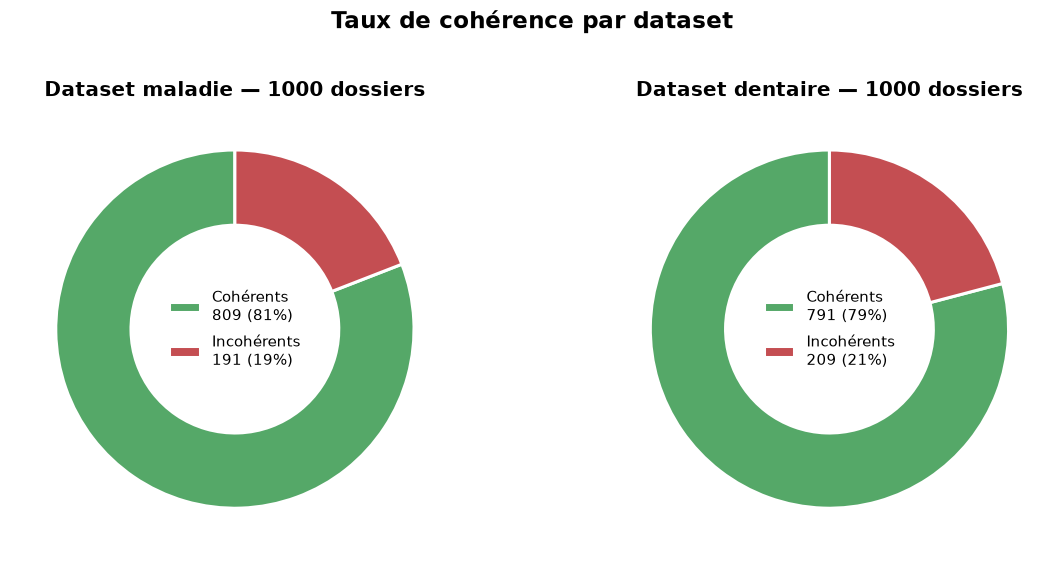

In [5]:
fig, axes = plt.subplots(1, len(datasets_disponibles), figsize=(5.5 * len(datasets_disponibles), 5))
if len(datasets_disponibles) == 1:
    axes = [axes]

for ax, (nom, df) in zip(axes, datasets_disponibles.items()):
    nb_coherent = df["coherent"].sum()
    nb_incoherent = len(df) - nb_coherent
    valeurs = [nb_coherent, nb_incoherent]
    labels = [f"Cohérents\n{nb_coherent} ({100*nb_coherent/len(df):.0f}%)",
              f"Incohérents\n{nb_incoherent} ({100*nb_incoherent/len(df):.0f}%)"]

    wedges, _ = ax.pie(
        valeurs, colors=[COULEUR_COHERENT, COULEUR_INCOHERENT],
        startangle=90, wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
    )
    ax.legend(wedges, labels, loc="center", fontsize=10, frameon=False)
    ax.set_title(f"Dataset {nom} — {len(df)} dossiers")

fig.suptitle("Taux de cohérence par dataset", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
FIGURES_A_EXPORTER["01_taux_coherence"] = fig
plt.show()

## 3. Répartition des types d'erreur

Point à vérifier particulièrement : si un type d'erreur attendu (d'après
le cahier des charges) n'apparaît jamais, c'est probablement un bug du
générateur de dataset plutôt qu'une absence normale.

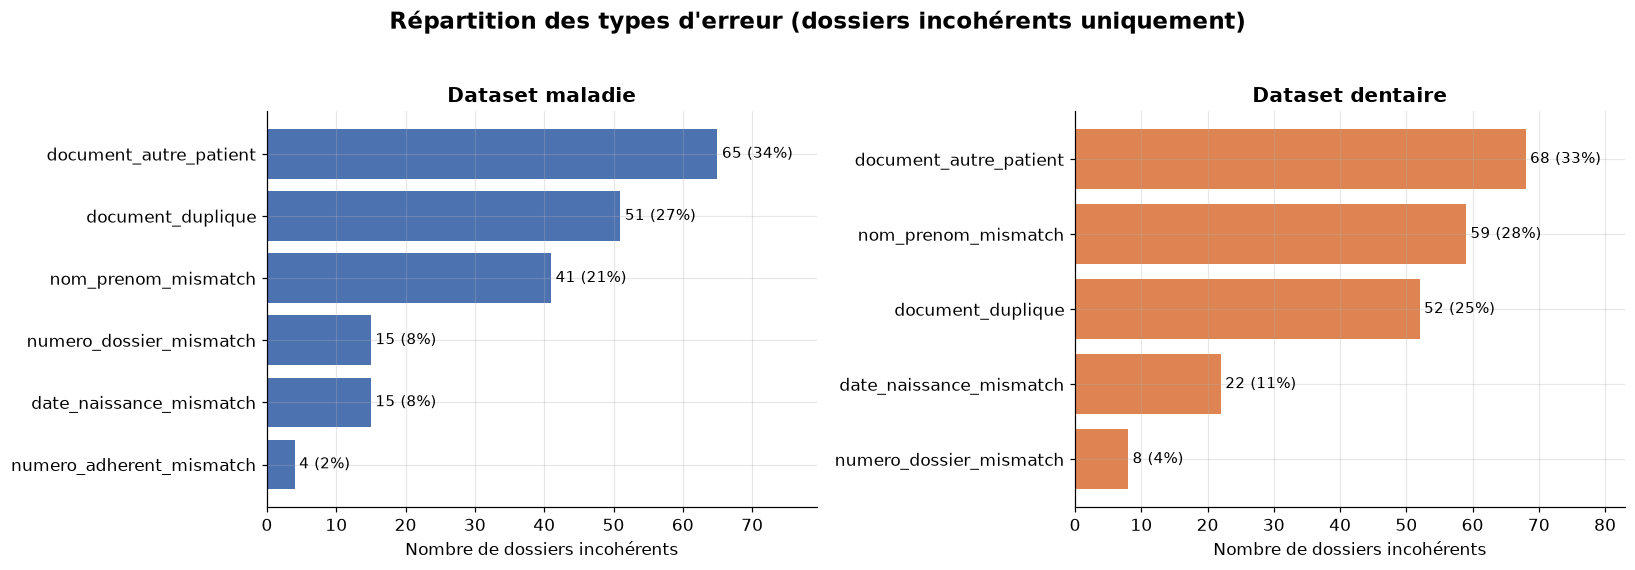

In [6]:
fig, axes = plt.subplots(1, len(datasets_disponibles), figsize=(7.5 * len(datasets_disponibles), 5))
if len(datasets_disponibles) == 1:
    axes = [axes]

for ax, (nom, df) in zip(axes, datasets_disponibles.items()):
    erreurs = df.loc[~df["coherent"], "type_erreur"].value_counts().sort_values()
    total_incoherents = erreurs.sum()
    barres = ax.barh(erreurs.index, erreurs.values, color=COULEUR[nom])

    for barre, valeur in zip(barres, erreurs.values):
        ax.text(barre.get_width() + max(erreurs.values) * 0.01, barre.get_y() + barre.get_height() / 2,
                f"{valeur} ({100*valeur/total_incoherents:.0f}%)", va="center", fontsize=9.5)

    ax.set_title(f"Dataset {nom}")
    ax.set_xlabel("Nombre de dossiers incohérents")
    ax.set_xlim(0, max(erreurs.values) * 1.22)

fig.suptitle("Répartition des types d'erreur (dossiers incohérents uniquement)",
             fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
FIGURES_A_EXPORTER["02_types_erreur"] = fig
plt.show()

## 4. Distribution du nombre de pages par dossier

Un nombre de pages supérieur au maximum attendu est un signal fort de
document dupliqué -- on distingue ici les dossiers cohérents des
incohérents pour voir si cette hypothèse se vérifie visuellement.

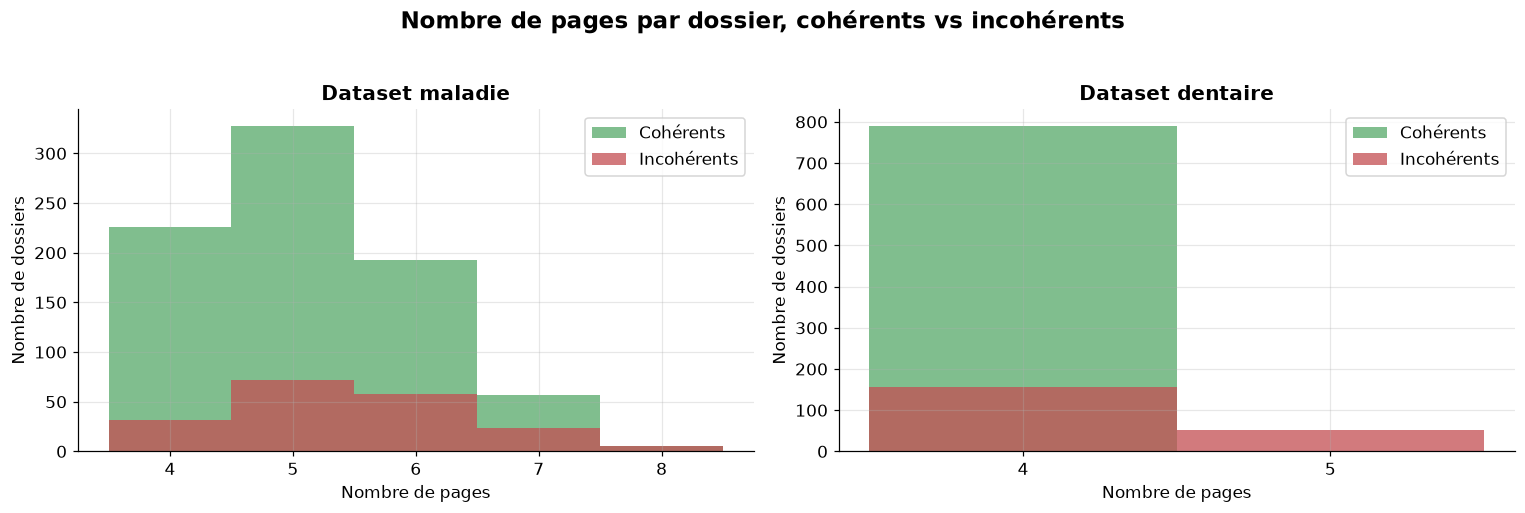

In [7]:
fig, axes = plt.subplots(1, len(datasets_disponibles), figsize=(7 * len(datasets_disponibles), 4.5))
if len(datasets_disponibles) == 1:
    axes = [axes]

for ax, (nom, df) in zip(axes, datasets_disponibles.items()):
    pages_min, pages_max = df["nombre_pages"].min(), df["nombre_pages"].max()
    bins = range(pages_min, pages_max + 2)

    ax.hist(df.loc[df["coherent"], "nombre_pages"], bins=bins, align="left",
            color=COULEUR_COHERENT, alpha=0.75, label="Cohérents")
    ax.hist(df.loc[~df["coherent"], "nombre_pages"], bins=bins, align="left",
            color=COULEUR_INCOHERENT, alpha=0.75, label="Incohérents")

    ax.set_title(f"Dataset {nom}")
    ax.set_xlabel("Nombre de pages")
    ax.set_ylabel("Nombre de dossiers")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.legend()

fig.suptitle("Nombre de pages par dossier, cohérents vs incohérents",
             fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
FIGURES_A_EXPORTER["03_distribution_pages"] = fig
plt.show()

## 5. Fréquence des catégories de documents

Utile surtout pour le dataset maladie, où plusieurs documents sont
optionnels (analyses, prise en charge, formulaire longue durée, radio) :
montre le taux de tirage réel de chacun. Une fréquence au-dessus de 100%
n'est pas une erreur -- c'est la signature d'un document dupliqué (deux
occurrences de la même catégorie dans un seul dossier).

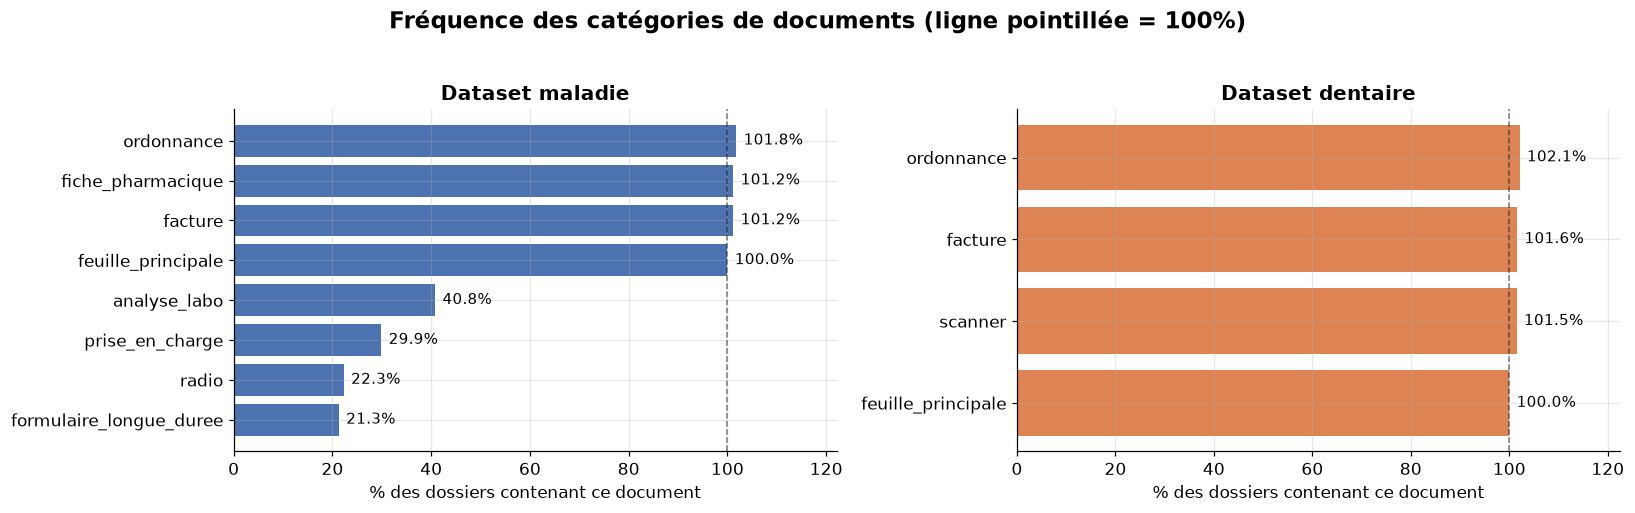

In [8]:
fig, axes = plt.subplots(1, len(datasets_disponibles), figsize=(7.5 * len(datasets_disponibles), 4.5))
if len(datasets_disponibles) == 1:
    axes = [axes]

for ax, (nom, df) in zip(axes, datasets_disponibles.items()):
    compteur = Counter()
    for categories in df["categories"]:
        compteur.update(categories)
    freq = pd.Series(compteur).sort_values() / len(df) * 100

    barres = ax.barh(freq.index, freq.values, color=COULEUR[nom])
    ax.axvline(100, color="black", linewidth=1, linestyle="--", alpha=0.5)
    for barre, valeur in zip(barres, freq.values):
        ax.text(barre.get_width() + 1.5, barre.get_y() + barre.get_height() / 2,
                f"{valeur:.1f}%", va="center", fontsize=9.5)

    ax.set_title(f"Dataset {nom}")
    ax.set_xlabel("% des dossiers contenant ce document")
    ax.set_xlim(0, max(freq.values) * 1.2)

fig.suptitle("Fréquence des catégories de documents (ligne pointillée = 100%)",
             fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
FIGURES_A_EXPORTER["04_frequence_categories"] = fig
plt.show()

## 6. Pages dupliquées vs nombre de pages

Vérifie si les dossiers `document_duplique` ont bien un nombre de pages
supérieur à la normale -- et surtout, si cette distribution recoupe celle
des dossiers cohérents (ce qui rendrait une règle simple "trop de pages"
peu fiable pour détecter un doublon).

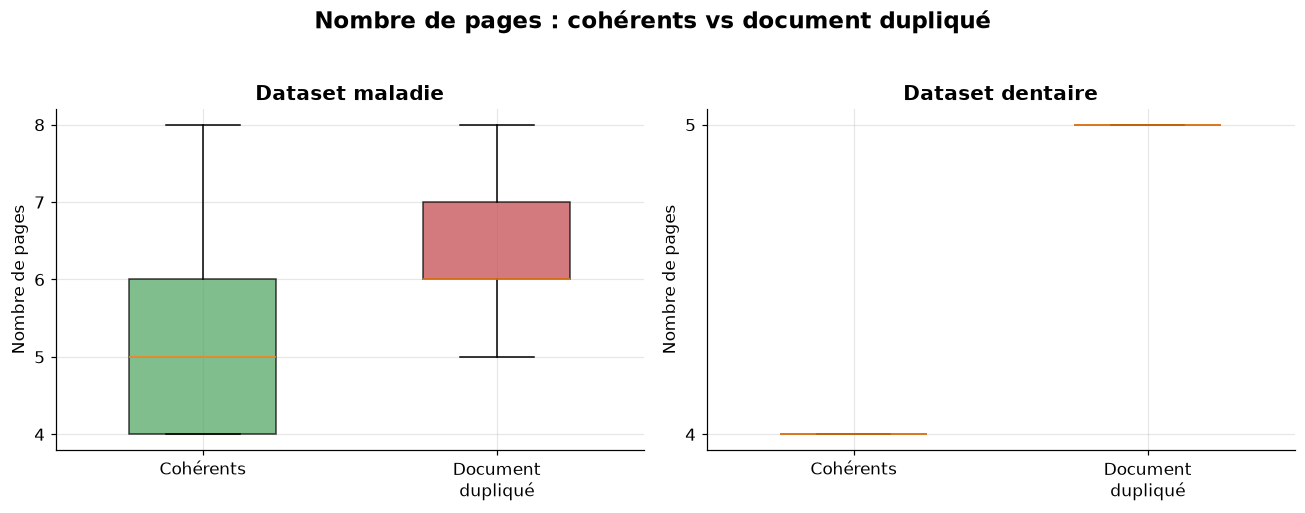

In [9]:
datasets_avec_duplique = {
    nom: df for nom, df in datasets_disponibles.items() if "document_duplique" in df["type_erreur"].values
}

if datasets_avec_duplique:
    fig, axes = plt.subplots(1, len(datasets_avec_duplique), figsize=(6 * len(datasets_avec_duplique), 4.5))
    if len(datasets_avec_duplique) == 1:
        axes = [axes]

    for ax, (nom, df) in zip(axes, datasets_avec_duplique.items()):
        groupes = [
            df.loc[df["coherent"], "nombre_pages"].values,
            df.loc[df["type_erreur"] == "document_duplique", "nombre_pages"].values,
        ]
        bp = ax.boxplot(groupes, tick_labels=["Cohérents", "Document\ndupliqué"], patch_artist=True, widths=0.5)
        for patch, couleur in zip(bp["boxes"], [COULEUR_COHERENT, COULEUR_INCOHERENT]):
            patch.set_facecolor(couleur)
            patch.set_alpha(0.75)
        ax.set_title(f"Dataset {nom}")
        ax.set_ylabel("Nombre de pages")
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    fig.suptitle("Nombre de pages : cohérents vs document dupliqué",
                 fontsize=15, fontweight="bold", y=1.03)
    plt.tight_layout()
    FIGURES_A_EXPORTER["05_pages_vs_duplique"] = fig
    plt.show()
else:
    print("Aucun dataset chargé ne contient de dossier 'document_duplique'.")

## 7. Anomalies structurelles du dataset

Types d'erreur totalement absents ou anormalement rares par rapport à une
répartition équiprobable attendue -- signe probable d'un bug dans le
générateur plutôt que d'une coïncidence statistique.

In [10]:
for nom, df in datasets_disponibles.items():
    print(f"--- {nom} ---")
    incoherents = df.loc[~df["coherent"]]
    nb_types = incoherents["type_erreur"].nunique()
    attendu_si_equiprobable = len(incoherents) / nb_types if nb_types else 0

    compte = incoherents["type_erreur"].value_counts()
    for type_erreur, effectif in compte.items():
        alerte = " <-- anormalement rare" if effectif < attendu_si_equiprobable * 0.3 else ""
        print(f"  {type_erreur:30s} {effectif:5d}  (attendu si équiprobable : ~{attendu_si_equiprobable:.0f}){alerte}")
    print()

--- maladie ---
  document_autre_patient            65  (attendu si équiprobable : ~32)
  document_duplique                 51  (attendu si équiprobable : ~32)
  nom_prenom_mismatch               41  (attendu si équiprobable : ~32)
  date_naissance_mismatch           15  (attendu si équiprobable : ~32)
  numero_dossier_mismatch           15  (attendu si équiprobable : ~32)
  numero_adherent_mismatch           4  (attendu si équiprobable : ~32) <-- anormalement rare

--- dentaire ---
  document_autre_patient            68  (attendu si équiprobable : ~42)
  nom_prenom_mismatch               59  (attendu si équiprobable : ~42)
  document_duplique                 52  (attendu si équiprobable : ~42)
  date_naissance_mismatch           22  (attendu si équiprobable : ~42)
  numero_dossier_mismatch            8  (attendu si équiprobable : ~42) <-- anormalement rare



## 8. Sélection de l'échantillon de test stratifié

Les dossiers déjà utilisés pour construire et ajuster le code (étapes
2-3-4) sont exclus d'office : les inclure donnerait une précision/rappel
artificiellement optimiste.

**Échantillonnage stratifié plutôt que purement aléatoire.** Certains
types d'erreur sont très rares -- un tirage aléatoire simple risque de ne
jamais les inclure. On garantit donc un minimum de dossiers pour CHAQUE
type d'erreur présent, plus un lot de dossiers cohérents à part.

In [11]:
DOSSIERS_DEJA_UTILISES = {
    "Dossier_000001.pdf", "Dossier_000005.pdf", "Dossier_000009.pdf",
    "Dossier_000022.pdf", "Dossier_000032.pdf", "Dossier_000034.pdf",
}

GRAINE_ALEATOIRE = 42
N_PAR_TYPE_ERREUR = 5
NB_DOSSIERS_COHERENTS = 20

echantillons_test = {}

for nom, df in datasets_disponibles.items():
    df_disponible = df[~df["fichier"].isin(DOSSIERS_DEJA_UTILISES)]

    morceaux = []
    types_presents = df_disponible.loc[~df_disponible["coherent"], "type_erreur"].unique()
    for type_erreur in sorted(types_presents):
        groupe = df_disponible[df_disponible["type_erreur"] == type_erreur]
        n = min(N_PAR_TYPE_ERREUR, len(groupe))
        morceaux.append(groupe.sample(n=n, random_state=GRAINE_ALEATOIRE))

    groupe_coherent = df_disponible[df_disponible["coherent"]]
    n_coherent = min(NB_DOSSIERS_COHERENTS, len(groupe_coherent))
    morceaux.append(groupe_coherent.sample(n=n_coherent, random_state=GRAINE_ALEATOIRE))

    echantillon = pd.concat(morceaux).sample(frac=1, random_state=GRAINE_ALEATOIRE)
    echantillons_test[nom] = echantillon

    print(f"\n{nom} — échantillon stratifié ({len(echantillon)} dossiers) :")
    print(f"  Cohérents : {echantillon['coherent'].sum()} / Incohérents : {(~echantillon['coherent']).sum()}")
    print("  Répartition par type d'erreur :")
    print(f"  {echantillon.loc[~echantillon['coherent'], 'type_erreur'].value_counts().to_dict()}")

    chemin_liste = Path(f"../outputs/echantillon_test_{nom}.txt")
    chemin_liste.parent.mkdir(parents=True, exist_ok=True)
    chemin_liste.write_text("\n".join(sorted(echantillon["fichier"])), encoding="utf-8")
    print(f"  Liste sauvegardée : {chemin_liste}")


maladie — échantillon stratifié (49 dossiers) :
  Cohérents : 20 / Incohérents : 29
  Répartition par type d'erreur :
  {'document_duplique': 5, 'nom_prenom_mismatch': 5, 'numero_dossier_mismatch': 5, 'date_naissance_mismatch': 5, 'document_autre_patient': 5, 'numero_adherent_mismatch': 4}
  Liste sauvegardée : ..\outputs\echantillon_test_maladie.txt

dentaire — échantillon stratifié (45 dossiers) :
  Cohérents : 20 / Incohérents : 25
  Répartition par type d'erreur :
  {'date_naissance_mismatch': 5, 'document_duplique': 5, 'document_autre_patient': 5, 'numero_dossier_mismatch': 5, 'nom_prenom_mismatch': 5}
  Liste sauvegardée : ..\outputs\echantillon_test_dentaire.txt


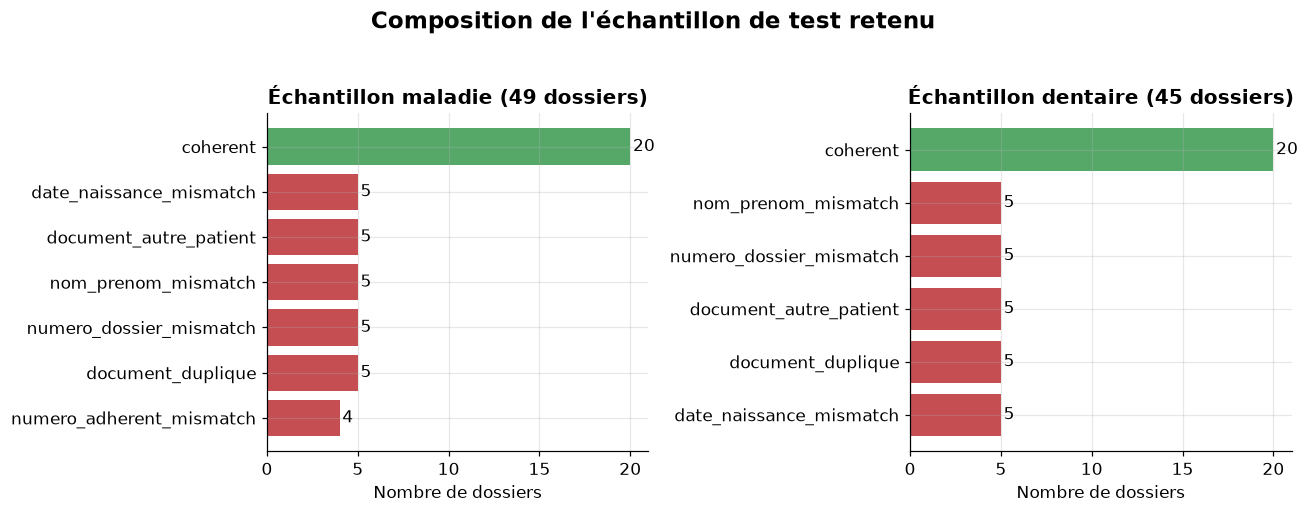

In [12]:
# Visualisation de la composition de l'échantillon retenu, par dataset
fig, axes = plt.subplots(1, len(echantillons_test), figsize=(6 * len(echantillons_test), 4.5))
if len(echantillons_test) == 1:
    axes = [axes]

for ax, (nom, echantillon) in zip(axes, echantillons_test.items()):
    compte = echantillon["type_erreur"].fillna("coherent").value_counts().sort_values()
    couleurs = [COULEUR_COHERENT if t == "coherent" else COULEUR_INCOHERENT for t in compte.index]
    barres = ax.barh(compte.index, compte.values, color=couleurs)
    for barre, valeur in zip(barres, compte.values):
        ax.text(barre.get_width() + 0.15, barre.get_y() + barre.get_height() / 2, str(valeur), va="center")
    ax.set_title(f"Échantillon {nom} ({len(echantillon)} dossiers)")
    ax.set_xlabel("Nombre de dossiers")

fig.suptitle("Composition de l'échantillon de test retenu", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
FIGURES_A_EXPORTER["06_composition_echantillon"] = fig
plt.show()

## 9. Export des figures pour le rapport

Sauvegarde toutes les figures de ce notebook en PNG haute résolution dans
`docs/figures/`, directement réutilisables dans le rapport de stage sans
avoir à faire des captures d'écran.

In [13]:
for nom_fichier, fig in FIGURES_A_EXPORTER.items():
    chemin = FIGURES_DIR / f"{nom_fichier}.png"
    fig.savefig(chemin, dpi=200, bbox_inches="tight")
    print(f"Exporté : {chemin}")

Exporté : ..\docs\figures\01_taux_coherence.png
Exporté : ..\docs\figures\02_types_erreur.png
Exporté : ..\docs\figures\03_distribution_pages.png
Exporté : ..\docs\figures\04_frequence_categories.png
Exporté : ..\docs\figures\05_pages_vs_duplique.png
Exporté : ..\docs\figures\06_composition_echantillon.png


## À faire ensuite

- **Vérifier le générateur de dataset avant d'aller plus loin** si un type
  d'erreur ressort comme anormalement rare ou absent (section 7) --
  probablement un bug dans la logique de tirage du type d'erreur.
- Le notebook `01_ocr_extraction.ipynb` lit
  `outputs/echantillon_test_<dataset>.txt` pour son traitement par lot --
  relancer la section 8 régénère cet échantillon si besoin (avec la même
  graine aléatoire, donc de façon reproductible).